# tests d'extraction STL

on genere des series avec des parametres connus (periode, pente, amplitude, bruit) et on verifie que STL les retrouve. on fait varier un parametre a la fois, les autres restant fixes, et on compare la valeur estimee a la valeur vraie.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL, MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.tsatools import detrend
from scipy.signal import find_peaks, periodogram

from series_utils import generate_series

## fonction d'extraction

la periode est estimee par le pic de l'autocorrelation apres retrait de la tendance (l'ACF sur la serie brute est biaisee par la tendance). ensuite STL donne la tendance, la saisonnalite et le residu, dont on tire la pente, l'amplitude et le bruit.



cf : l'autocorrélation mesure à quel point x[t] et x[t+h] varient ensemble. Quand la série a une tendance croissante, x[t] et x[t+h] sont tous les deux tirés vers le haut par cette dérive commune : au début de la série les deux sont bas, à la fin les deux sont hauts. Ils co-varient donc fortement juste à cause de la tendance partagée, indépendamment de la saisonnalité.



In [ ]:
from series_utils import estimate_period

def extract(series):
    period = estimate_period(series)
    res = STL(series, period=period, robust=True).fit()
    trend = series - detrend(series, order=1)
    t = np.arange(len(series))
    valid = ~np.isnan(trend)
    slope = np.polyfit(t[valid], trend[valid], 1)[0] 
    amplitude = (res.seasonal.max() - res.seasonal.min()) / 2
    noise = np.nanstd(res.resid)
    return dict(periode=period, pente=slope, amplitude=amplitude, bruit=noise)

## balayage des parametres

on part d'une configuration de base et on fait varier chaque parametre un a un. pour chaque valeur, on genere la serie, on extrait, et on garde la valeur vraie et la valeur estimee du parametre que l'on fait varier.

In [31]:
base = dict(trend_slope=0.01, seasonal_amplitude=1.0, seasonal_period=50, noise_std=0.15)

sweeps = {
    "pente": ("trend_slope", np.linspace(0.0, 0.2, 25)),
    "amplitude": ("seasonal_amplitude", np.linspace(0.5, 10.0, 25)),
    "periode": ("seasonal_period", np.arange(20, 301, 8)),
    "bruit": ("noise_std", np.linspace(0.02, 1.0, 25)),
}

rows = []
for param, (key, values) in sweeps.items():
    for value in values:
        params = dict(base)
        params[key] = value
        rng = np.random.default_rng(0)
        _, series = generate_series(5000, rng=rng, **params)
        estimee = extract(series)[param]
        rows.append(dict(parametre=param, valeur_vraie=value, valeur_estimee=estimee))

results = pd.DataFrame(rows)
results.round(3)

,parametre,valeur_vraie,valeur_estimee
0,pente,0.000,-0.000
1,pente,0.008,0.008
2,pente,0.017,0.017
3,pente,0.025,0.025
4,pente,0.033,0.033
...,...,...,...
106,bruit,0.837,0.705
107,bruit,0.878,0.739
108,bruit,0.918,0.773
109,bruit,0.959,0.807


## comparaison valeur vraie vs estimee

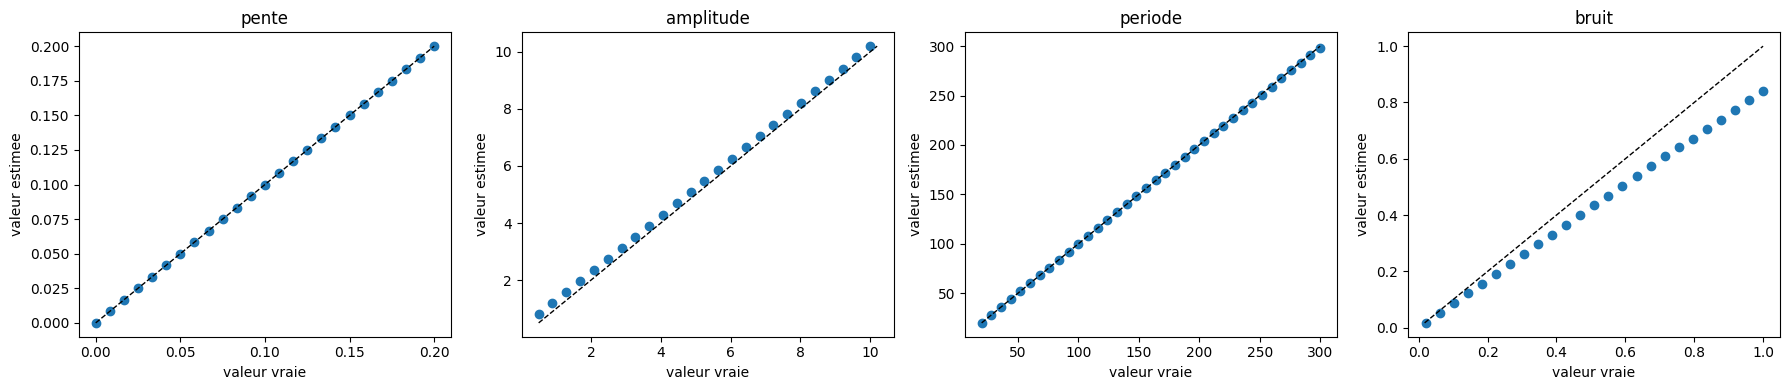

In [32]:
params = ["pente", "amplitude", "periode", "bruit"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, param in zip(axes, params):
    sub = results[results["parametre"] == param]
    ax.scatter(sub["valeur_vraie"], sub["valeur_estimee"])
    lo = min(sub["valeur_vraie"].min(), sub["valeur_estimee"].min())
    hi = max(sub["valeur_vraie"].max(), sub["valeur_estimee"].max())
    ax.plot([lo, hi], [lo, hi], "k--", linewidth=1)
    ax.set_title(param)
    ax.set_xlabel("valeur vraie")
    ax.set_ylabel("valeur estimee")
plt.tight_layout()
plt.show()

Le bruit est estimé comme l'écart-type du résidu : $\hat\sigma = \mathrm{std}(x - \text{tendance} - \text{saisonnalité})$. 

Quand le bruit est fort, peut etre que la saisonnalité en capte une partie (ce qui pourrait expliquer l'ecart pour les bruits élevés.)

## saisonnalite : valeur estimee vs vraie

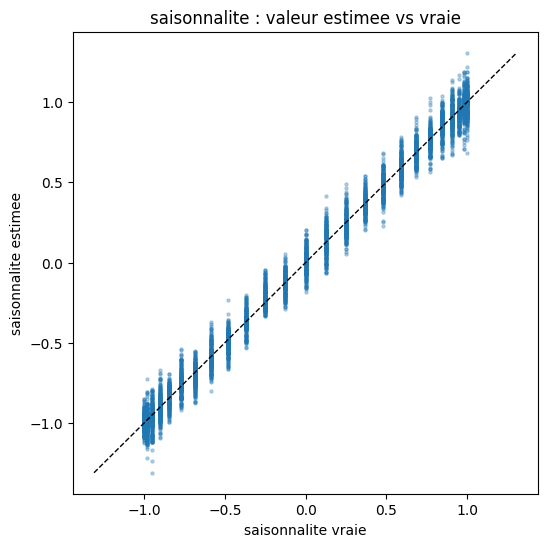

In [33]:
params_exemple = dict(trend_slope=0.01, seasonal_amplitude=1.0, seasonal_period=50, noise_std=0.15)
rng = np.random.default_rng(0)
t, serie_exemple = generate_series(5000, rng=rng, **params_exemple)

periode = estimate_period(serie_exemple)
res = STL(serie_exemple, period=periode, robust=True).fit()

saison_estimee = res.seasonal
saison_vraie = params_exemple["seasonal_amplitude"] * np.sin(2 * np.pi * t / params_exemple["seasonal_period"])

plt.figure(figsize=(6, 6))
plt.scatter(saison_vraie, saison_estimee, s=5, alpha=0.3)
lo = min(saison_vraie.min(), saison_estimee.min())
hi = max(saison_vraie.max(), saison_estimee.max())
plt.plot([lo, hi], [lo, hi], "k--", linewidth=1)
plt.xlabel("saisonnalite vraie")
plt.ylabel("saisonnalite estimee")
plt.title("saisonnalite : valeur estimee vs vraie")
plt.show()

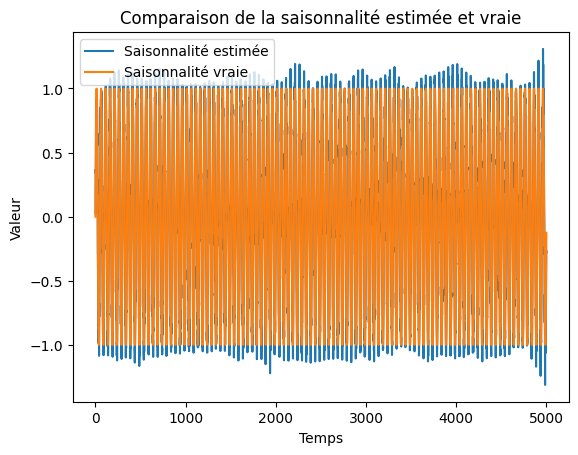

In [34]:
#tracé de la saisonnalité estimée et de la saisonnalité vraie
plt.plot(saison_estimee, label='Saisonnalité estimée')
plt.plot(saison_vraie, label='Saisonnalité vraie')
plt.legend()
plt.title('Comparaison de la saisonnalité estimée et vraie')
plt.xlabel('Temps')
plt.ylabel('Valeur')
plt.show()

## test MSTL : serie a deux periodes

STL ne gere qu'une saisonnalite, MSTL en gere plusieurs.

In [64]:
t2, serie_2p = generate_series(1680, trend_slope=0.005, seasonal_amplitude=1.0, seasonal_period=24, noise_std=0.2, rng=np.random.default_rng(0))
serie_2p = serie_2p + 0.6 * np.sin(2 * np.pi * t2 / 168)

## periodogramme : detecter les periodes


In [65]:
f, power = periodogram(detrend(serie_2p, order=1))
periodes = 1 / f[1:]
puissance = power[1:]

ordre = np.argsort(puissance)[::-1]
periodes_detectees = []
for i in ordre:
    per = int(round(periodes[i]))
    if all(abs(per - autre) > 5 for autre in periodes_detectees):
        periodes_detectees.append(per)
    if len(periodes_detectees) == 2:
        break
periodes_detectees = sorted(periodes_detectees)
print("periodes detectees :", periodes_detectees)

periodes detectees : [24, 168]


## extraction MSTL

on passe les periodes detectees a MSTL, qui separe les deux saisonnalites.

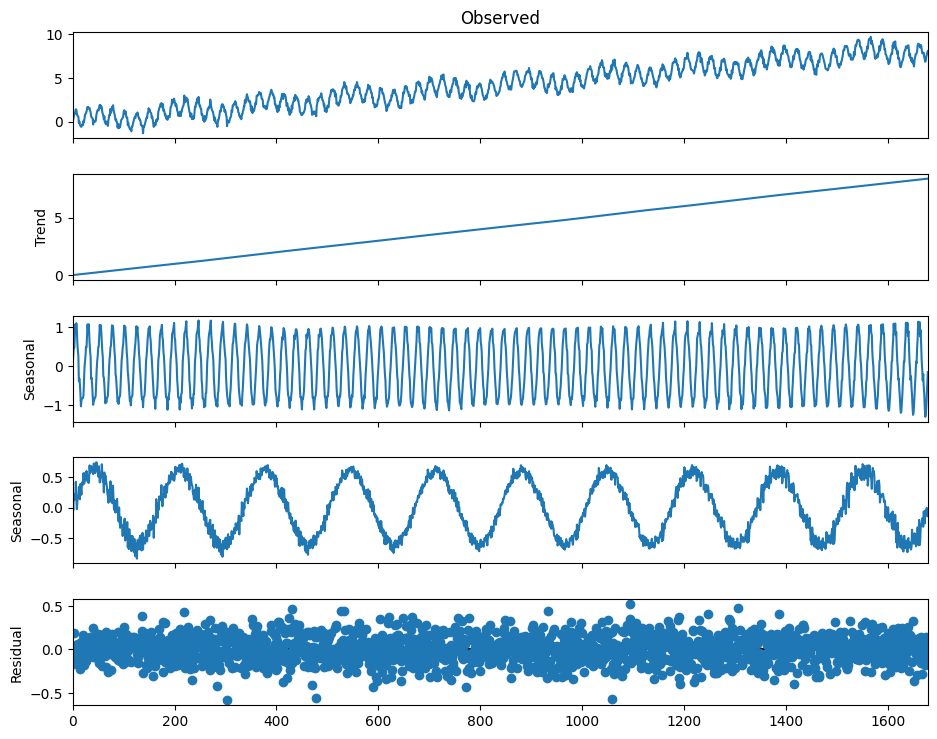

In [66]:
res_mstl = MSTL(serie_2p, periods=tuple(periodes_detectees)).fit()

fig = res_mstl.plot()
fig.set_size_inches(10, 8)
plt.show()